# Notebook 2: Decision Tree, Random Forest, Evaluation and Comparison
**Assignment 1 – Predicting Breast Cancer with Decision Trees and Random Forests**

Requires the files created by `01_exploration_preprocessing.ipynb` (folder `data/processed/`).

**Contents**
1. Load processed data
2. Decision Tree – construction (baseline, tuning, final model)
3. Decision Tree – visualization and interpretation
4. Decision Tree – evaluation and limitations
5. Random Forest – construction and tuning
6. Comparison: Random Forest vs Decision Tree (accuracy, robustness, generalization)
7. Random Forest – visualization and interpretation
8. Conclusions

## 1. Load Processed Data

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_val_score, learning_curve)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_curve, auc)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
os.makedirs("outputs/figures", exist_ok=True)
CLASS_NAMES = ["Benign", "Malignant"]
COL_DT, COL_RF = "#E08A3C", "#3A7CA5"      # colours: Decision Tree = orange, Random Forest = blue

X_train = pd.read_csv("data/processed/X_train.csv")
X_test  = pd.read_csv("data/processed/X_test.csv")
X_train_s = pd.read_csv("data/processed/X_train_scaled.csv")
X_test_s  = pd.read_csv("data/processed/X_test_scaled.csv")
y_train = pd.read_csv("data/processed/y_train.csv").squeeze()
y_test  = pd.read_csv("data/processed/y_test.csv").squeeze()
features = json.load(open("data/processed/selected_features.json"))

print("Train:", X_train.shape, "| Test:", X_test.shape, "| Features:", len(features))

Train: (455, 20) | Test: (114, 20) | Features: 20


In [2]:
# Helper that computes every metric for a fitted model (positive class = Malignant)
def evaluate(model, X_tr, y_tr, X_te, y_te, name):
    pred_tr, pred_te = model.predict(X_tr), model.predict(X_te)
    proba_te = model.predict_proba(X_te)[:, 1]
    return {"Model": name,
            "Train Accuracy": accuracy_score(y_tr, pred_tr),
            "Test Accuracy": accuracy_score(y_te, pred_te),
            "Precision": precision_score(y_te, pred_te),
            "Recall": recall_score(y_te, pred_te),
            "F1-score": f1_score(y_te, pred_te),
            "ROC-AUC": roc_auc_score(y_te, proba_te)}

## 2. Decision Tree – Construction

**Process followed**
1. *Data preprocessing* – done in Notebook 1 (cleaning, target encoding, scaling, stratified 80/20 split).
2. *Feature selection* – correlated features removed in Notebook 1; the tree itself then performs *embedded* selection by choosing the best feature at each split.
3. *Model training* – CART algorithm: at every node the split that gives the largest reduction in impurity (Gini or entropy) is chosen, recursively, until a stopping rule is reached.
4. *Hyper-parameter tuning* – 5-fold stratified cross-validation on the training set only.

### 2.1 Baseline: unrestricted tree

In [3]:
dt_base = DecisionTreeClassifier(random_state=RANDOM_STATE)
dt_base.fit(X_train, y_train)

print("Depth of unrestricted tree :", dt_base.get_depth())
print("Number of leaves           :", dt_base.get_n_leaves())
print("Train accuracy:", round(dt_base.score(X_train, y_train), 4))
print("Test accuracy :", round(dt_base.score(X_test, y_test), 4))

Depth of unrestricted tree : 8
Number of leaves           : 22
Train accuracy: 1.0
Test accuracy : 0.9211


An unrestricted tree memorizes the training data (train accuracy = 100%), which is a sign of **overfitting**. Its test accuracy can look acceptable on one split, but the single split is noisy (one patient = ~0.9 percentage points), so we judge models using cross-validation and ROC-AUC as well, and control complexity by tuning.

### 2.2 Effect of tree depth (bias-variance trade-off)

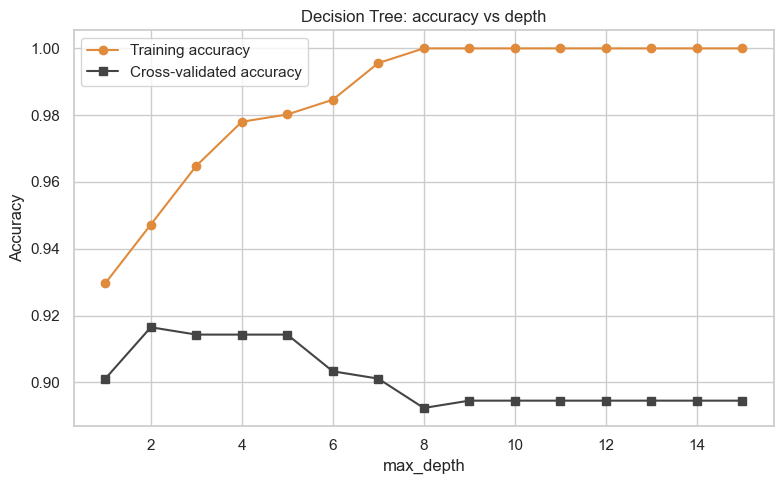

Best CV accuracy at depth: 2


In [4]:
depths = range(1, 16)
tr_acc, cv_acc = [], []
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)
    m.fit(X_train, y_train)
    tr_acc.append(m.score(X_train, y_train))
    cv_acc.append(cross_val_score(m, X_train, y_train, cv=skf, scoring="accuracy").mean())

plt.figure(figsize=(8, 5))
plt.plot(depths, tr_acc, "o-", label="Training accuracy", color=COL_DT)
plt.plot(depths, cv_acc, "s-", label="Cross-validated accuracy", color="#444")
plt.xlabel("max_depth"); plt.ylabel("Accuracy")
plt.title("Decision Tree: accuracy vs depth")
plt.legend(); plt.tight_layout()
plt.savefig("outputs/figures/11_dt_depth_curve.png", dpi=150)
plt.show()
print("Best CV accuracy at depth:", list(depths)[int(np.argmax(cv_acc))])

### 2.3 Hyper-parameter tuning (GridSearchCV)

In [5]:
param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [2, 3, 4, 5, 6, 8, None],
    "min_samples_leaf": [1, 2, 5, 10],
    "min_samples_split": [2, 5, 10],
    "ccp_alpha": [0.0, 0.005, 0.01, 0.02],      # cost-complexity (post-)pruning strength
}
dt_grid = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), param_grid,
                       cv=skf, scoring="f1", n_jobs=-1)
dt_grid.fit(X_train, y_train)

print("Best parameters :", dt_grid.best_params_)
print("Best CV F1-score:", round(dt_grid.best_score_, 4))
dt = dt_grid.best_estimator_         # final decision tree

Best parameters : {'ccp_alpha': 0.0, 'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 10, 'min_samples_split': 2}
Best CV F1-score: 0.9052


### 2.4 Does scaling change the tree? (empirical check)

In [6]:
dt_scaled = DecisionTreeClassifier(**dt_grid.best_params_, random_state=RANDOM_STATE).fit(X_train_s, y_train)
print("Test accuracy on raw features   :", round(dt.score(X_test, y_test), 4))
print("Test accuracy on scaled features:", round(dt_scaled.score(X_test_s, y_test), 4))
print("Identical predictions:", (dt.predict(X_test) == dt_scaled.predict(X_test_s)).all())

Test accuracy on raw features   : 0.9123
Test accuracy on scaled features: 0.9123
Identical predictions: True


Predictions are identical, which confirms that trees are scale-invariant. We use the **unscaled** features from here on so thresholds can be read in real measurement units.

## 3. Decision Tree – Visualization and Interpretation

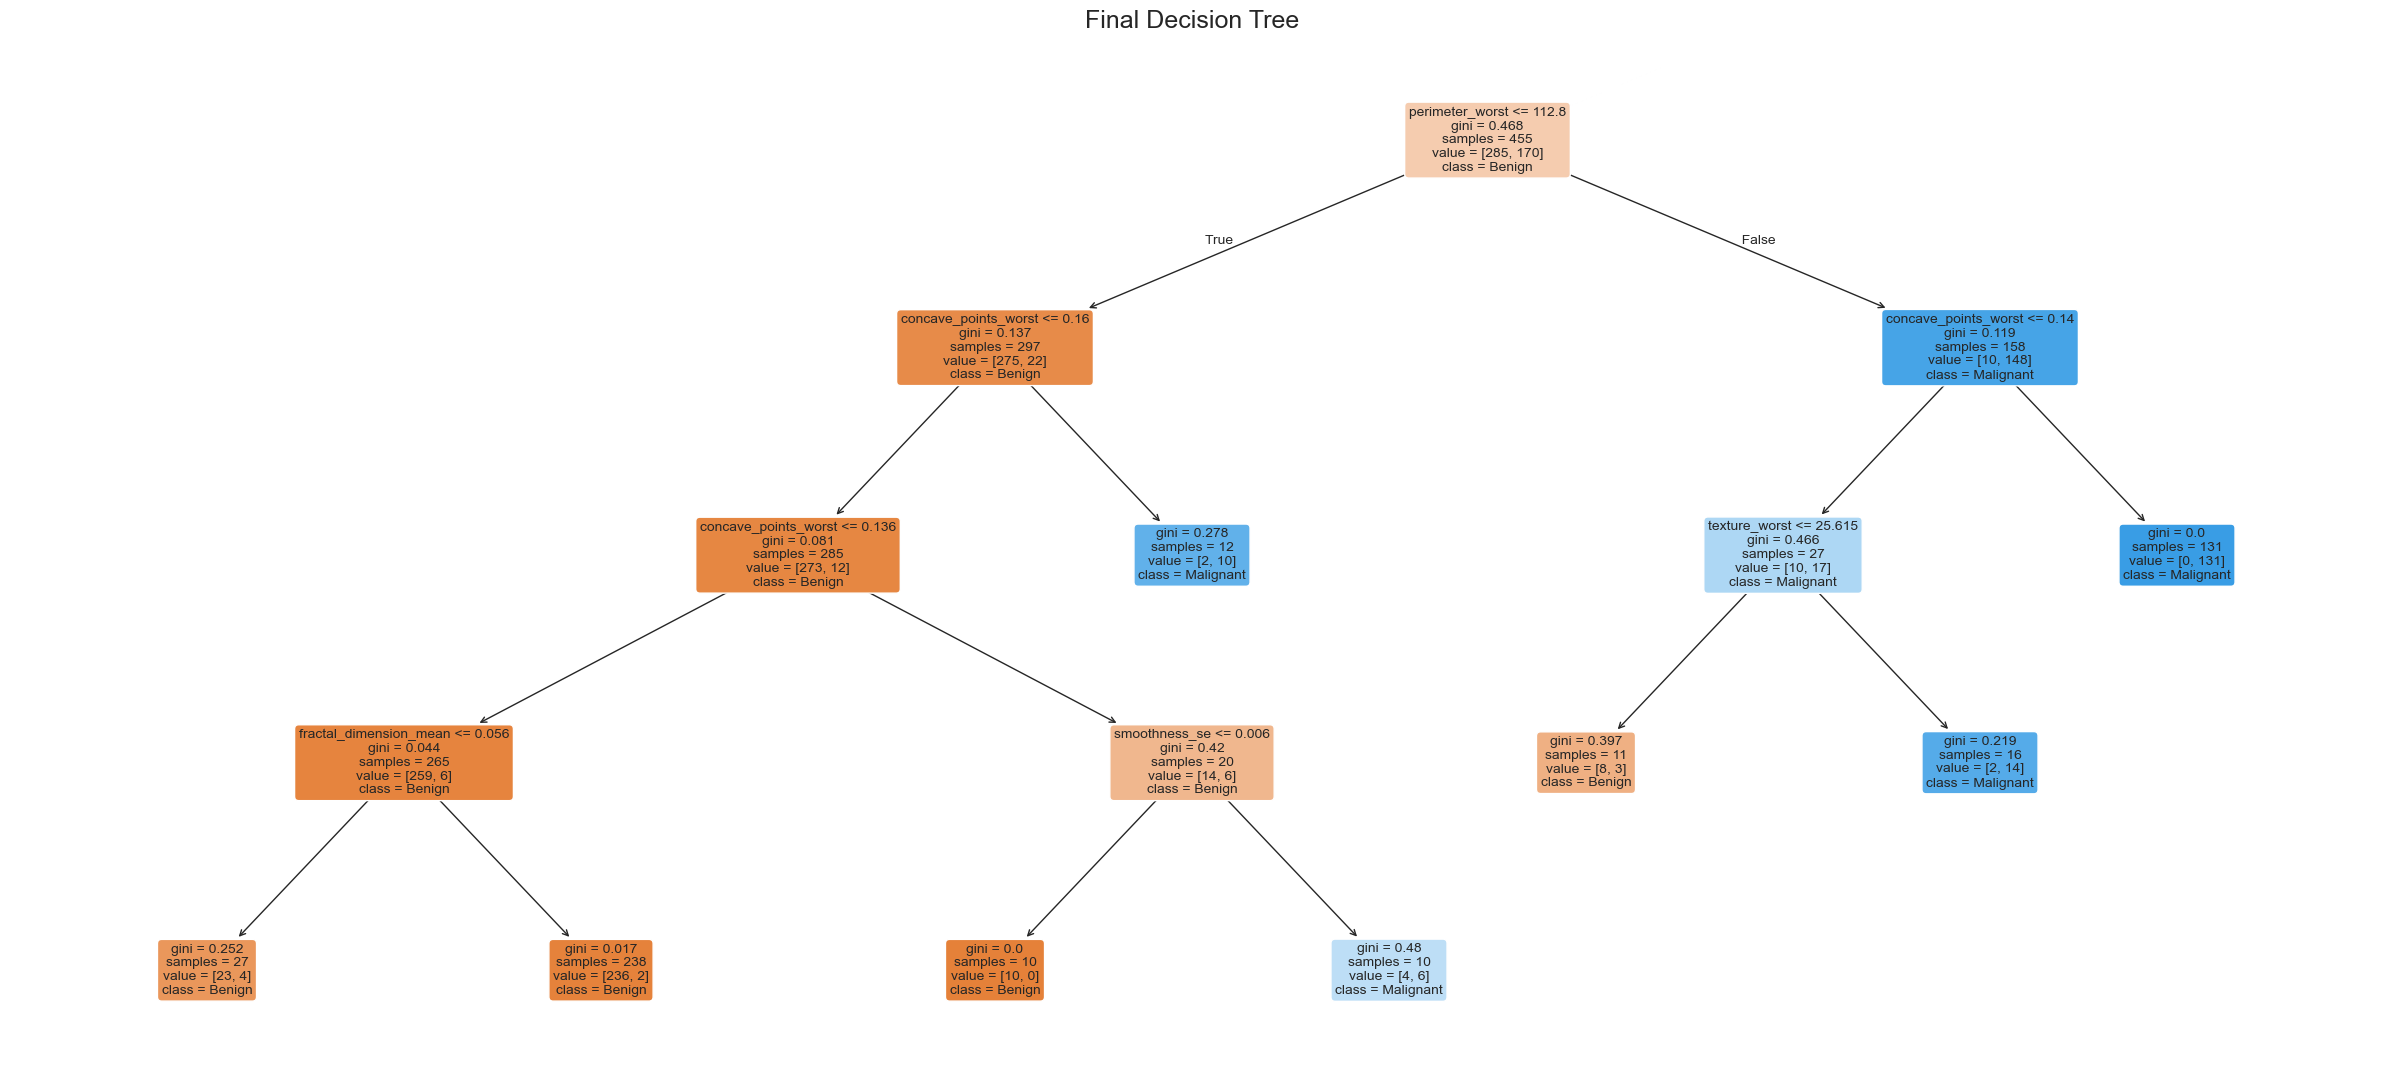

In [7]:
plt.figure(figsize=(24, 11))
plot_tree(dt, feature_names=features, class_names=CLASS_NAMES, filled=True, rounded=True,
          impurity=True, proportion=False, fontsize=10)
plt.title("Final Decision Tree", fontsize=18)
plt.tight_layout()
plt.savefig("outputs/figures/12_decision_tree.png", dpi=150)
plt.show()

In [8]:
# Text version of the rules
print(export_text(dt, feature_names=features, show_weights=True))

|--- perimeter_worst <= 112.80
|   |--- concave_points_worst <= 0.16
|   |   |--- concave_points_worst <= 0.14
|   |   |   |--- fractal_dimension_mean <= 0.06
|   |   |   |   |--- weights: [23.00, 4.00] class: 0
|   |   |   |--- fractal_dimension_mean >  0.06
|   |   |   |   |--- weights: [236.00, 2.00] class: 0
|   |   |--- concave_points_worst >  0.14
|   |   |   |--- smoothness_se <= 0.01
|   |   |   |   |--- weights: [10.00, 0.00] class: 0
|   |   |   |--- smoothness_se >  0.01
|   |   |   |   |--- weights: [4.00, 6.00] class: 1
|   |--- concave_points_worst >  0.16
|   |   |--- weights: [2.00, 10.00] class: 1
|--- perimeter_worst >  112.80
|   |--- concave_points_worst <= 0.14
|   |   |--- texture_worst <= 25.61
|   |   |   |--- weights: [8.00, 3.00] class: 0
|   |   |--- texture_worst >  25.61
|   |   |   |--- weights: [2.00, 14.00] class: 1
|   |--- concave_points_worst >  0.14
|   |   |--- weights: [0.00, 131.00] class: 1



In [9]:
# Automatic summary of the tree structure
t = dt.tree_
root_feat = features[t.feature[0]]
print(f"Depth: {dt.get_depth()} | Leaves: {dt.get_n_leaves()} | Total nodes: {t.node_count}")
print(f"Root split: '{root_feat}' <= {t.threshold[0]:.3f}")
print(f"  -> left child  ({t.n_node_samples[t.children_left[0]]} training samples)")
print(f"  -> right child ({t.n_node_samples[t.children_right[0]]} training samples)")
print("\nFeatures actually used by the tree:", sorted({features[i] for i in t.feature if i >= 0}))

Depth: 4 | Leaves: 8 | Total nodes: 15
Root split: 'perimeter_worst' <= 112.800
  -> left child  (297 training samples)
  -> right child (158 training samples)

Features actually used by the tree: ['concave_points_worst', 'fractal_dimension_mean', 'perimeter_worst', 'smoothness_se', 'texture_worst']


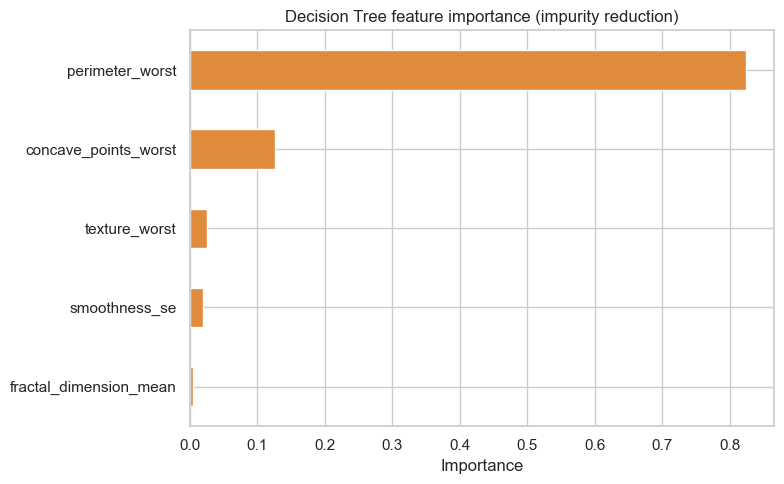

perimeter_worst           0.824
concave_points_worst      0.126
texture_worst             0.025
smoothness_se             0.019
fractal_dimension_mean    0.005
dtype: float64

In [10]:
# Decision Tree feature importance
imp_dt = pd.Series(dt.feature_importances_, index=features).sort_values()
imp_dt = imp_dt[imp_dt > 0]
plt.figure(figsize=(8, 5))
imp_dt.plot.barh(color=COL_DT)
plt.title("Decision Tree feature importance (impurity reduction)")
plt.xlabel("Importance"); plt.tight_layout()
plt.savefig("outputs/figures/13_dt_feature_importance.png", dpi=150)
plt.show()
imp_dt.sort_values(ascending=False).round(3)

**How to read the tree**
- Each box shows the split rule, the Gini impurity, the number of training samples, the class counts, and the majority class (colour = class, darker = purer).
- The **root split** is the single most informative question for separating benign from malignant tumours. Features near the top carry the most weight.
- Leaves with low impurity are confident predictions; leaves with higher impurity mark borderline cases where the two classes overlap.
- The tree is easy to explain as a set of if-then rules, which is its main advantage over the random forest.

## 4. Decision Tree – Evaluation

In [11]:
y_pred_dt = dt.predict(X_test)
y_prob_dt = dt.predict_proba(X_test)[:, 1]

print("Decision Tree - test set results")
print("Accuracy :", round(accuracy_score(y_test, y_pred_dt), 4))
print("Precision:", round(precision_score(y_test, y_pred_dt), 4))
print("Recall   :", round(recall_score(y_test, y_pred_dt), 4))
print("F1-score :", round(f1_score(y_test, y_pred_dt), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob_dt), 4))
print("\n", classification_report(y_test, y_pred_dt, target_names=CLASS_NAMES))

Decision Tree - test set results
Accuracy : 0.9123
Precision: 0.9444
Recall   : 0.8095
F1-score : 0.8718
ROC-AUC  : 0.9416

               precision    recall  f1-score   support

      Benign       0.90      0.97      0.93        72
   Malignant       0.94      0.81      0.87        42

    accuracy                           0.91       114
   macro avg       0.92      0.89      0.90       114
weighted avg       0.91      0.91      0.91       114



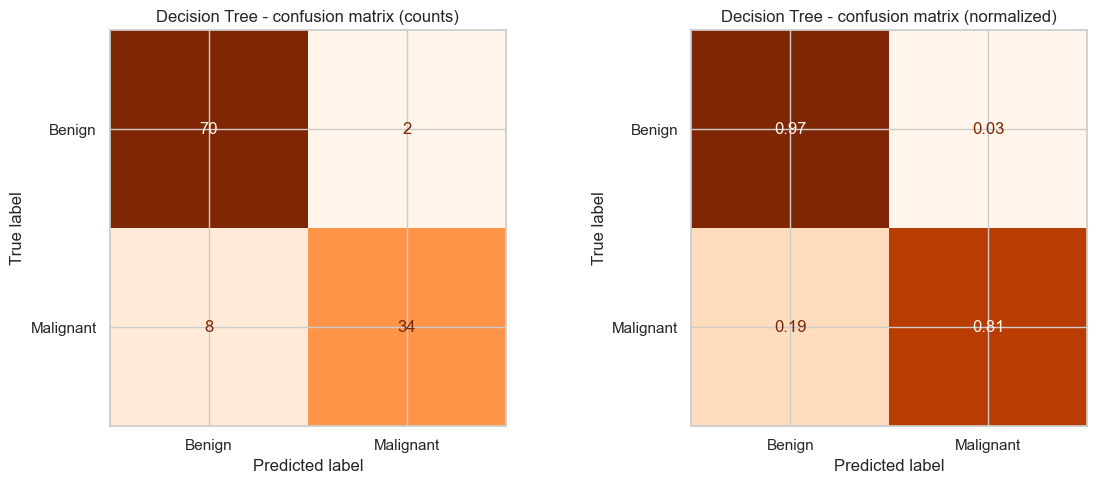

True negatives=70, False positives=2, False negatives=8 (missed cancers), True positives=34


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_dt, display_labels=CLASS_NAMES,
                                        cmap="Oranges", ax=axes[0], colorbar=False)
axes[0].set_title("Decision Tree - confusion matrix (counts)")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_dt, display_labels=CLASS_NAMES, normalize="true",
                                        cmap="Oranges", ax=axes[1], colorbar=False, values_format=".2f")
axes[1].set_title("Decision Tree - confusion matrix (normalized)")
plt.tight_layout()
plt.savefig("outputs/figures/14_dt_confusion_matrix.png", dpi=150)
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_dt).ravel()
print(f"True negatives={tn}, False positives={fp}, False negatives={fn} (missed cancers), True positives={tp}")

In [13]:
# Cross-validation on the full training data for a more reliable estimate
cv_scores = {m: cross_val_score(dt, X_train, y_train, cv=skf, scoring=m)
             for m in ["accuracy", "precision", "recall", "f1"]}
pd.DataFrame({k: [v.mean(), v.std()] for k, v in cv_scores.items()}, index=["mean", "std"]).round(4)

,accuracy,precision,recall,f1
mean,0.9297,0.9077,0.9059,0.9052
std,0.0292,0.0433,0.0655,0.0399


### Limitations and challenges of the Decision Tree
- **High variance / instability:** a small change in the training data can produce a very different tree. The depth curve and cross-validation standard deviation illustrate this.
- **Overfitting:** the unrestricted tree reaches 100% training accuracy but generalizes worse; it had to be controlled with depth limits and pruning.
- **Axis-aligned splits:** each split uses one feature, so diagonal or smooth decision boundaries are approximated with many steps.
- **Small dataset:** with only 114 test cases, one extra mistake changes accuracy by ~0.9 percentage points, so single-split results are noisy (hence the cross-validation).
- **Class imbalance:** about 37% malignant; accuracy alone can hide poor recall, so precision, recall, F1 and ROC-AUC are reported.
- **Clinical cost of errors:** a false negative (missed malignant tumour) is far more serious than a false positive, so recall on the malignant class is the metric to watch.
- **Hyper-parameter tuning cost:** the grid search was large relative to the data size and must be done only on the training set to avoid leakage.

## 5. Random Forest – Construction

**How a random forest enhances the single tree**
- **Bagging (bootstrap aggregation):** each tree is trained on a random bootstrap sample of the training rows (sampling with replacement).
- **Random feature subsets:** at each split only a random subset of features (`max_features`) is considered, which decorrelates the trees.
- **Combining trees:** for classification, every tree votes and the final prediction is the majority vote (scikit-learn averages the class probabilities of the trees).
- **Out-of-bag (OOB) samples:** rows left out of each bootstrap sample give a free internal validation estimate.

The averaging of many de-correlated, high-variance trees lowers the variance of the ensemble without increasing bias much.

### 5.1 Baseline random forest

In [14]:
rf_base = RandomForestClassifier(n_estimators=100, oob_score=True, random_state=RANDOM_STATE, n_jobs=-1)
rf_base.fit(X_train, y_train)
print("Baseline RF - train accuracy:", round(rf_base.score(X_train, y_train), 4))
print("Baseline RF - OOB accuracy  :", round(rf_base.oob_score_, 4))
print("Baseline RF - test accuracy :", round(rf_base.score(X_test, y_test), 4))

Baseline RF - train accuracy: 1.0
Baseline RF - OOB accuracy  : 0.9604
Baseline RF - test accuracy : 0.9474


### 5.2 Effect of the number of trees

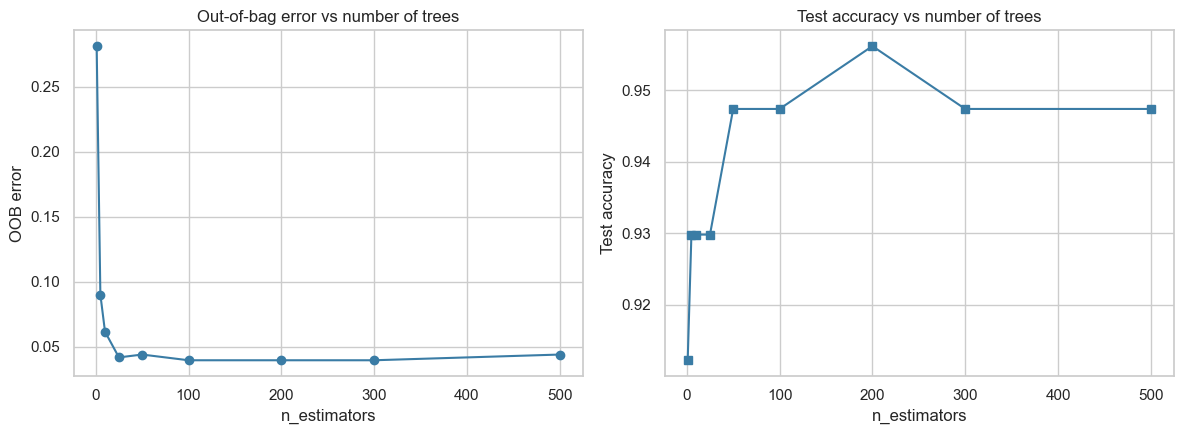

In [15]:
n_list = [1, 5, 10, 25, 50, 100, 200, 300, 500]
oob_err, test_acc = [], []
for n in n_list:
    m = RandomForestClassifier(n_estimators=n, oob_score=True, bootstrap=True,
                               random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
    # with very few trees some rows may never be out-of-bag; sklearn warns but still returns a value
    oob_err.append(1 - m.oob_score_)
    test_acc.append(m.score(X_test, y_test))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(n_list, oob_err, "o-", color=COL_RF); axes[0].set_title("Out-of-bag error vs number of trees")
axes[0].set_xlabel("n_estimators"); axes[0].set_ylabel("OOB error")
axes[1].plot(n_list, test_acc, "s-", color=COL_RF); axes[1].set_title("Test accuracy vs number of trees")
axes[1].set_xlabel("n_estimators"); axes[1].set_ylabel("Test accuracy")
plt.tight_layout()
plt.savefig("outputs/figures/15_rf_n_estimators.png", dpi=150)
plt.show()

The error falls quickly and then flattens, so beyond a few hundred trees there is little benefit from adding more, only extra computation.

### 5.3 Hyper-parameter tuning (GridSearchCV)

In [16]:
rf_grid_params = {
    "n_estimators": [100, 300],
    "max_depth": [None, 6, 10],
    "max_features": ["sqrt", 0.5],
    "min_samples_leaf": [1, 2, 4],
}
rf_grid = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
                       rf_grid_params, cv=skf, scoring="f1", n_jobs=-1)
rf_grid.fit(X_train, y_train)

print("Best parameters :", rf_grid.best_params_)
print("Best CV F1-score:", round(rf_grid.best_score_, 4))
rf = rf_grid.best_estimator_        # final random forest

Best parameters : {'max_depth': 6, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 100}
Best CV F1-score: 0.9502


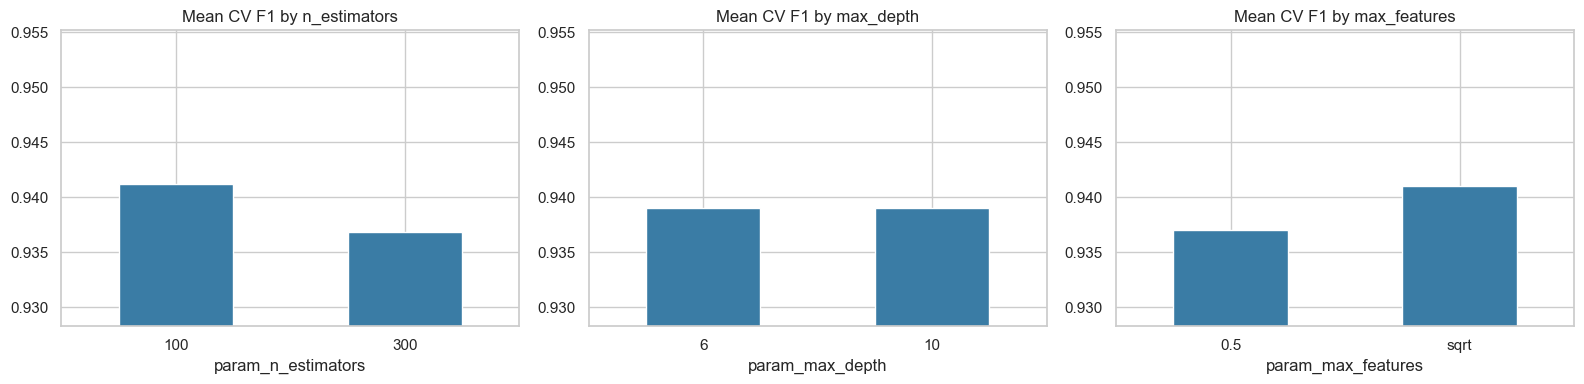

In [17]:
# Importance of each tuned hyper-parameter value (mean CV F1 per setting)
res = pd.DataFrame(rf_grid.cv_results_)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, p in zip(axes, ["param_n_estimators", "param_max_depth", "param_max_features"]):
    res.groupby(p)["mean_test_score"].mean().plot.bar(ax=ax, color=COL_RF)
    ax.set_title(f"Mean CV F1 by {p.replace('param_', '')}")
    ax.set_ylim(res["mean_test_score"].min() - 0.005, res["mean_test_score"].max() + 0.005)
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("outputs/figures/16_rf_tuning.png", dpi=150)
plt.show()

## 6. Comparison: Random Forest vs Decision Tree

### 6.1 Performance metrics on the test set

In [18]:
rf_final = RandomForestClassifier(**rf_grid.best_params_, oob_score=True, random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
results = pd.DataFrame([
    evaluate(dt_base, X_train, y_train, X_test, y_test, "Decision Tree (unrestricted)"),
    evaluate(dt, X_train, y_train, X_test, y_test, "Decision Tree (tuned)"),
    evaluate(rf_base, X_train, y_train, X_test, y_test, "Random Forest (baseline)"),
    evaluate(rf_final, X_train, y_train, X_test, y_test, "Random Forest (tuned)"),
]).set_index("Model").round(4)
results.to_csv("outputs/model_comparison.csv")
print("Random Forest OOB accuracy (tuned):", round(rf_final.oob_score_, 4))
results

Random Forest OOB accuracy (tuned): 0.9604


,Train Accuracy,Test Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,,
Decision Tree (unrestricted),1.0000,0.9211,0.9459,0.8333,0.8861,0.9028
Decision Tree (tuned),0.9626,0.9123,0.9444,0.8095,0.8718,0.9416
Random Forest (baseline),1.0000,0.9474,1.0000,0.8571,0.9231,0.9972
Random Forest (tuned),0.9956,0.9561,1.0000,0.8810,0.9367,0.9967


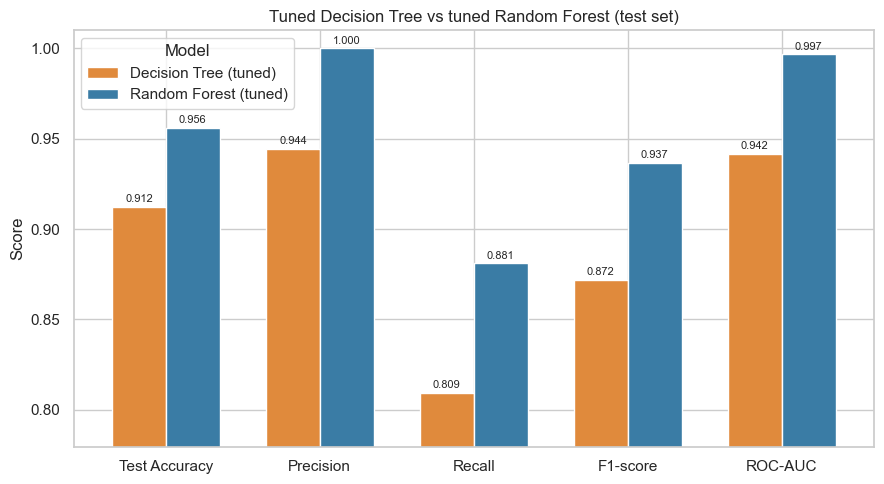

In [19]:
metrics = ["Test Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
comp = results.loc[["Decision Tree (tuned)", "Random Forest (tuned)"], metrics].T
ax = comp.plot.bar(figsize=(9, 5), color=[COL_DT, COL_RF], width=0.7)
ax.set_ylim(min(0.8, comp.values.min() - 0.03), 1.01)
ax.set_title("Tuned Decision Tree vs tuned Random Forest (test set)")
ax.set_ylabel("Score"); plt.xticks(rotation=0)
for c in ax.containers: ax.bar_label(c, fmt="%.3f", fontsize=8, padding=2)
plt.tight_layout()
plt.savefig("outputs/figures/17_metric_comparison.png", dpi=150)
plt.show()

### 6.2 Confusion matrices and ROC curves

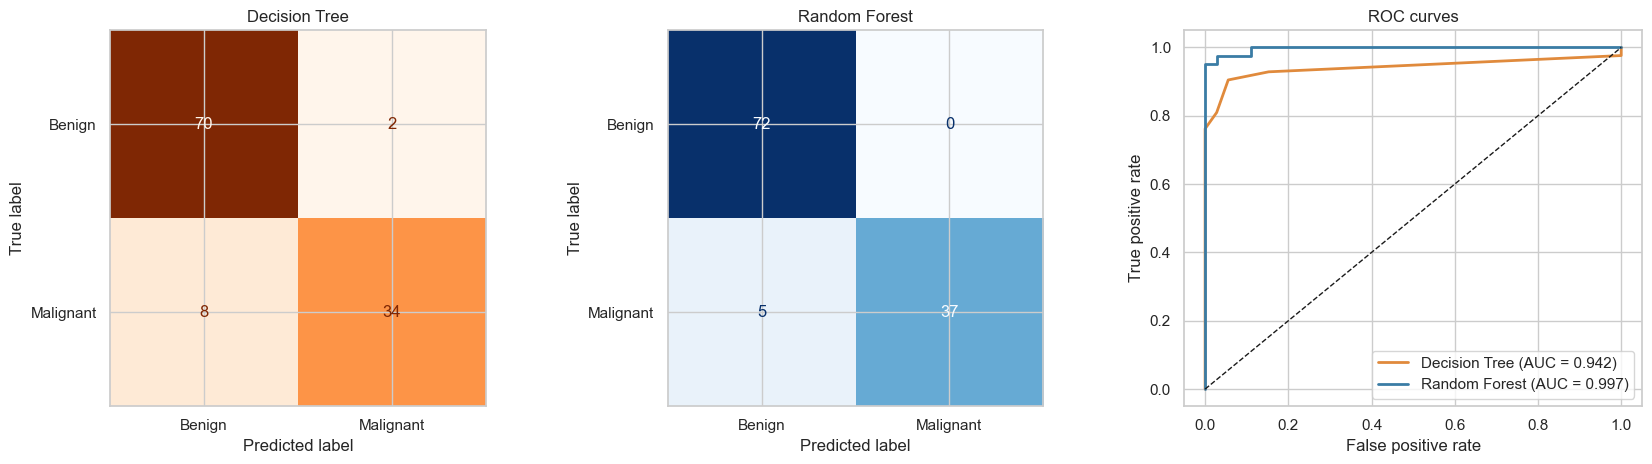

Decision Tree : missed cancers (FN) = 8, false alarms (FP) = 2, correct = 104/114
Random Forest : missed cancers (FN) = 5, false alarms (FP) = 0, correct = 109/114


In [20]:
y_pred_rf = rf_final.predict(X_test)
y_prob_rf = rf_final.predict_proba(X_test)[:, 1]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_dt, display_labels=CLASS_NAMES, cmap="Oranges", ax=axes[0], colorbar=False)
axes[0].set_title("Decision Tree")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf, display_labels=CLASS_NAMES, cmap="Blues", ax=axes[1], colorbar=False)
axes[1].set_title("Random Forest")
for name, prob, col in [("Decision Tree", y_prob_dt, COL_DT), ("Random Forest", y_prob_rf, COL_RF)]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[2].plot(fpr, tpr, color=col, lw=2, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")
axes[2].plot([0, 1], [0, 1], "k--", lw=1)
axes[2].set_xlabel("False positive rate"); axes[2].set_ylabel("True positive rate")
axes[2].set_title("ROC curves"); axes[2].legend(loc="lower right")
plt.tight_layout()
plt.savefig("outputs/figures/18_confusion_roc_comparison.png", dpi=150)
plt.show()

for name, p in [("Decision Tree", y_pred_dt), ("Random Forest", y_pred_rf)]:
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    print(f"{name:14s}: missed cancers (FN) = {fn}, false alarms (FP) = {fp}, correct = {tn + tp}/{len(y_test)}")

### 6.3 Robustness: repeated cross-validation
A single train/test split is noisy on 569 samples. Here every model is evaluated on **5 x 10 = 50 different splits**; a more robust model has a higher mean and a lower spread.

      Decision Tree  Random Forest
mean         0.9350         0.9547
std          0.0313         0.0225
min          0.8246         0.9123
max          1.0000         1.0000


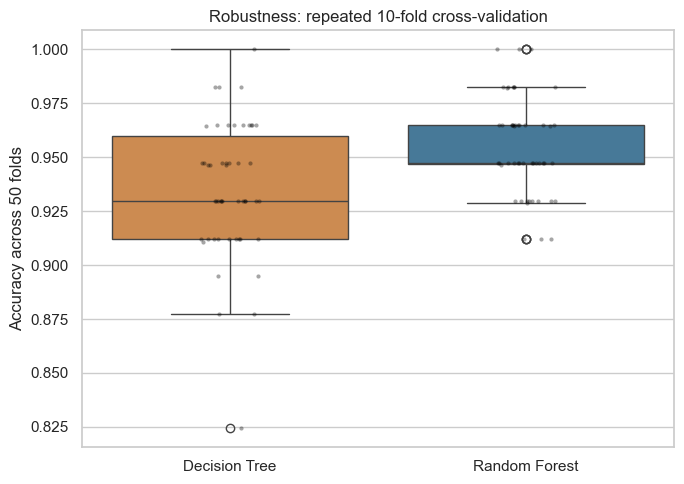

In [21]:
rcv = RepeatedStratifiedKFold(n_splits=10, n_repeats=5, random_state=RANDOM_STATE)
X_all = pd.concat([X_train, X_test]); y_all = pd.concat([y_train, y_test])

cv_dt = cross_val_score(DecisionTreeClassifier(**dt_grid.best_params_, random_state=RANDOM_STATE), X_all, y_all, cv=rcv, scoring="accuracy", n_jobs=-1)
cv_rf = cross_val_score(RandomForestClassifier(**rf_grid.best_params_, random_state=RANDOM_STATE, n_jobs=1), X_all, y_all, cv=rcv, scoring="accuracy", n_jobs=-1)

cv_df = pd.DataFrame({"Decision Tree": cv_dt, "Random Forest": cv_rf})
print(cv_df.agg(["mean", "std", "min", "max"]).round(4))

plt.figure(figsize=(7, 5))
sns.boxplot(data=cv_df, palette=[COL_DT, COL_RF])
sns.stripplot(data=cv_df, color="black", alpha=0.35, size=3)
plt.ylabel("Accuracy across 50 folds")
plt.title("Robustness: repeated 10-fold cross-validation")
plt.tight_layout()
plt.savefig("outputs/figures/19_robustness_cv.png", dpi=150)
plt.show()

### 6.4 Generalization: train-test gap and learning curves

In [22]:
gap = results.loc[["Decision Tree (unrestricted)", "Decision Tree (tuned)", "Random Forest (baseline)", "Random Forest (tuned)"],
                  ["Train Accuracy", "Test Accuracy"]].copy()
gap["Gap (train - test)"] = gap["Train Accuracy"] - gap["Test Accuracy"]
gap.round(4)

,Train Accuracy,Test Accuracy,Gap (train - test)
Model,,,
Decision Tree (unrestricted),1.0000,0.9211,0.0789
Decision Tree (tuned),0.9626,0.9123,0.0503
Random Forest (baseline),1.0000,0.9474,0.0526
Random Forest (tuned),0.9956,0.9561,0.0395


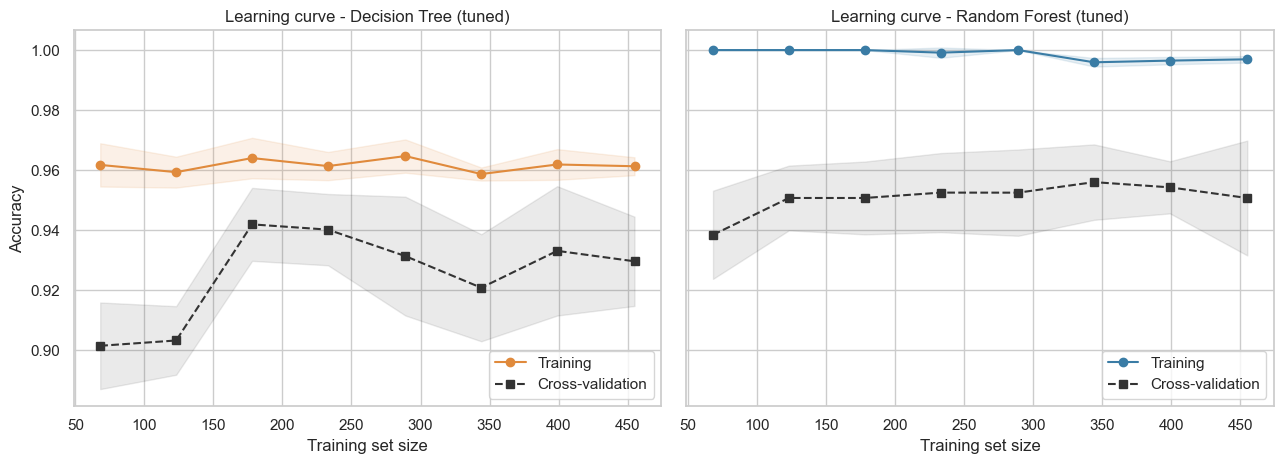

In [23]:
sizes = np.linspace(0.15, 1.0, 8)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, (name, model, col) in zip(axes, [
        ("Decision Tree (tuned)", DecisionTreeClassifier(**dt_grid.best_params_, random_state=RANDOM_STATE), COL_DT),
        ("Random Forest (tuned)", RandomForestClassifier(**rf_grid.best_params_, random_state=RANDOM_STATE, n_jobs=-1), COL_RF)]):
    ts, tr, va = learning_curve(model, X_all, y_all, train_sizes=sizes, cv=skf, scoring="accuracy", n_jobs=1)
    ax.plot(ts, tr.mean(1), "o-", color=col, label="Training")
    ax.fill_between(ts, tr.mean(1) - tr.std(1), tr.mean(1) + tr.std(1), color=col, alpha=0.12)
    ax.plot(ts, va.mean(1), "s--", color="#333", label="Cross-validation")
    ax.fill_between(ts, va.mean(1) - va.std(1), va.mean(1) + va.std(1), color="#333", alpha=0.10)
    ax.set_title(f"Learning curve - {name}"); ax.set_xlabel("Training set size"); ax.legend(loc="lower right")
axes[0].set_ylabel("Accuracy")
plt.tight_layout()
plt.savefig("outputs/figures/20_learning_curves.png", dpi=150)
plt.show()

### 6.5 Summary table of improvements

In [24]:
dt_row, rf_row = results.loc["Decision Tree (tuned)"], results.loc["Random Forest (tuned)"]
improve = pd.DataFrame({"Decision Tree": dt_row[metrics], "Random Forest": rf_row[metrics]})
improve["Change (RF - DT)"] = improve["Random Forest"] - improve["Decision Tree"]
improve.loc["CV accuracy (50 folds) - mean"] = [cv_dt.mean(), cv_rf.mean(), cv_rf.mean() - cv_dt.mean()]
improve.loc["CV accuracy (50 folds) - std (lower = more stable)"] = [cv_dt.std(), cv_rf.std(), cv_rf.std() - cv_dt.std()]
improve.round(4)

,Decision Tree,Random Forest,Change (RF - DT)
Test Accuracy,0.9123,0.9561,0.0438
Precision,0.9444,1.0000,0.0556
Recall,0.8095,0.8810,0.0715
F1-score,0.8718,0.9367,0.0649
ROC-AUC,0.9416,0.9967,0.0551
CV accuracy (50 folds) - mean,0.9350,0.9547,0.0197
CV accuracy (50 folds) - std (lower = more stable),0.0310,0.0222,-0.0088


## 7. Random Forest – Visualization and Interpretation
### 7.1 Feature importance (impurity-based) – compared with the single tree

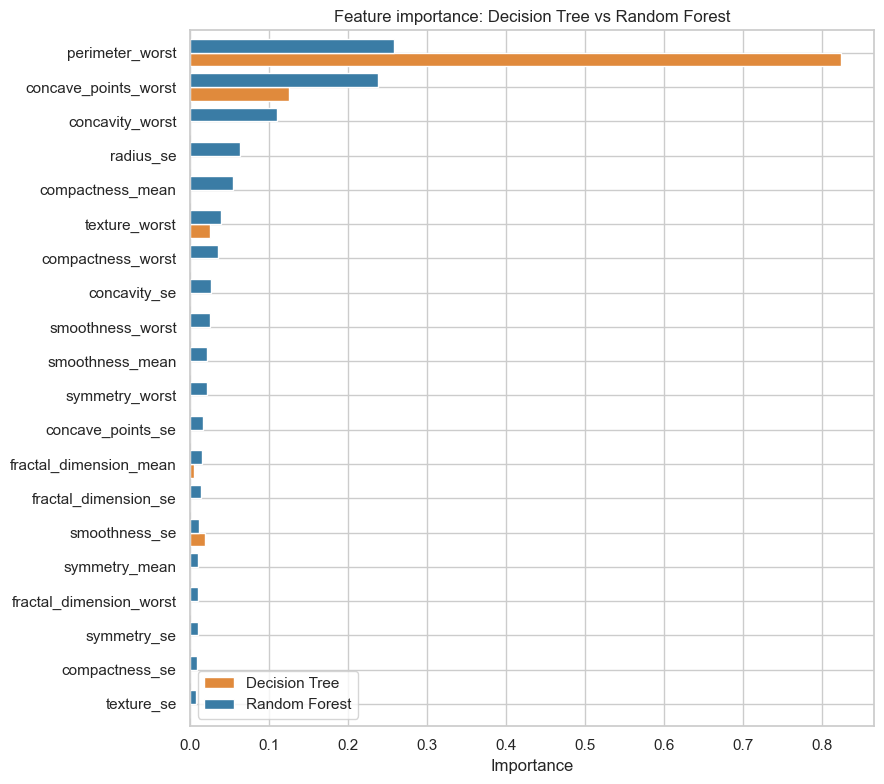

perimeter_worst         0.258
concave_points_worst    0.238
concavity_worst         0.110
radius_se               0.064
compactness_mean        0.055
texture_worst           0.039
compactness_worst       0.036
concavity_se            0.027
dtype: float64

In [25]:
imp_rf = pd.Series(rf_final.feature_importances_, index=features)
imp_cmp = pd.DataFrame({"Decision Tree": pd.Series(dt.feature_importances_, index=features), "Random Forest": imp_rf})
imp_cmp = imp_cmp.sort_values("Random Forest")
imp_cmp.plot.barh(figsize=(9, 8), color=[COL_DT, COL_RF], width=0.8)
plt.title("Feature importance: Decision Tree vs Random Forest")
plt.xlabel("Importance"); plt.tight_layout()
plt.savefig("outputs/figures/21_feature_importance_comparison.png", dpi=150)
plt.show()
imp_rf.sort_values(ascending=False).head(8).round(3)

The random forest spreads importance over more features than the single tree, which relies on only a few. This is expected: random feature subsets force trees to use many different predictors, giving a more stable ranking.

### 7.2 Permutation importance on the test set (more reliable than impurity importance)

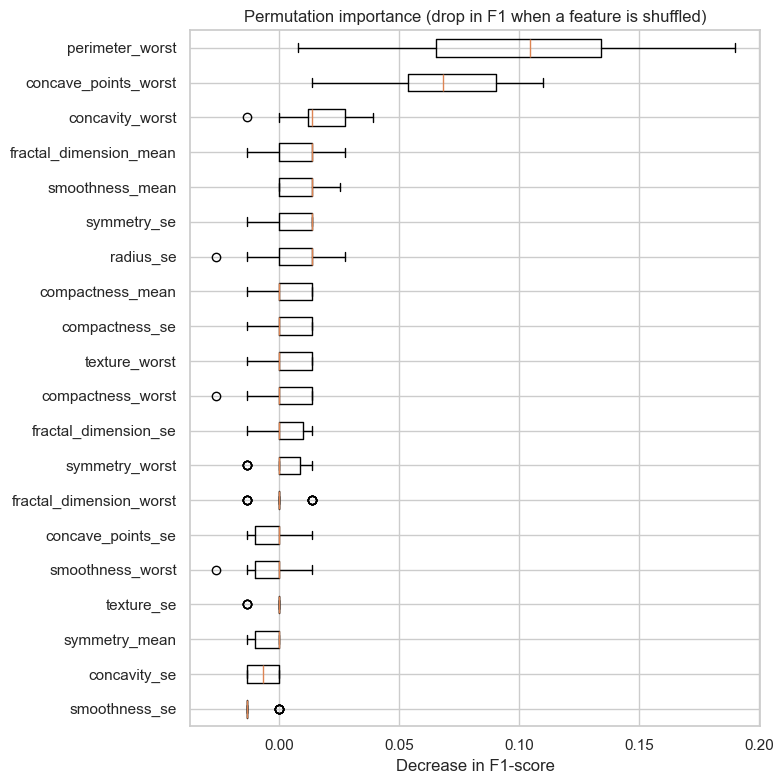

perimeter_worst           0.0998
concave_points_worst      0.0692
concavity_worst           0.0176
fractal_dimension_mean    0.0101
smoothness_mean           0.0098
dtype: float64

In [26]:
perm = permutation_importance(rf_final, X_test, y_test, n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1, scoring="f1")
perm_s = pd.Series(perm.importances_mean, index=features)
order = perm_s.sort_values().index
plt.figure(figsize=(8, 8))
plt.boxplot(perm.importances[[features.index(f) for f in order]].T, vert=False, labels=order)
plt.title("Permutation importance (drop in F1 when a feature is shuffled)")
plt.xlabel("Decrease in F1-score"); plt.tight_layout()
plt.savefig("outputs/figures/22_permutation_importance.png", dpi=150)
plt.show()
perm_s.sort_values(ascending=False).head(5).round(4)

### 7.3 One tree from the forest, and the prediction probability distribution

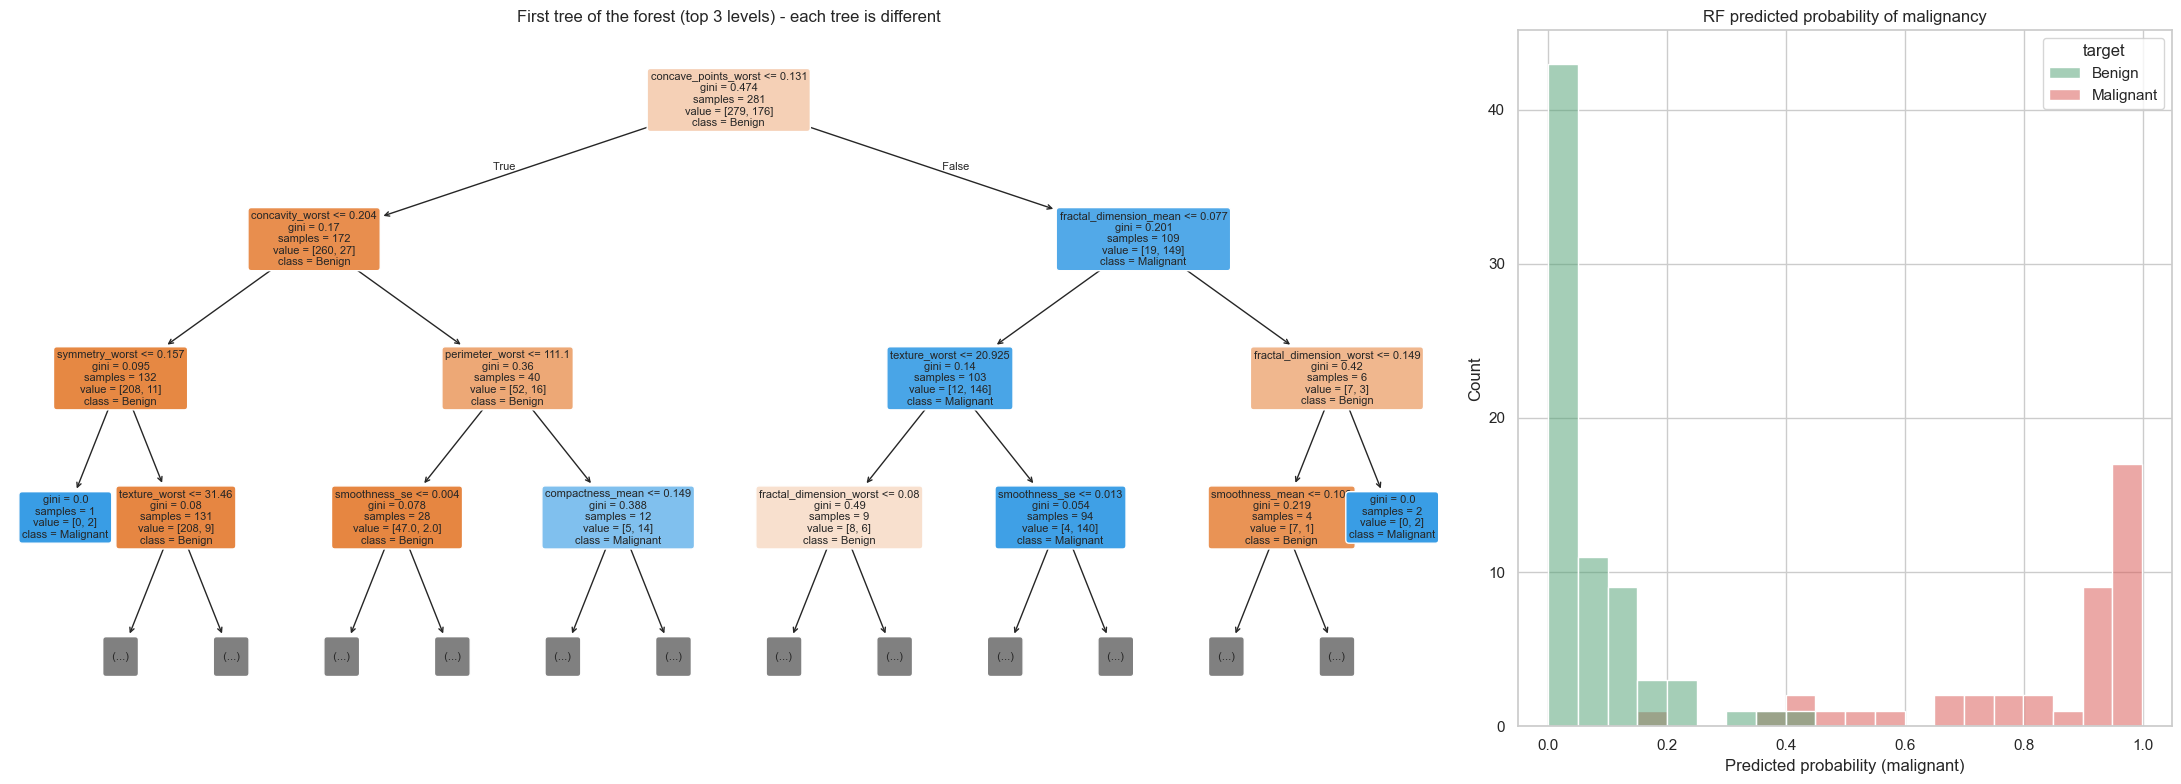

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(22, 8), gridspec_kw={"width_ratios": [2.2, 1]})
plot_tree(rf_final.estimators_[0], feature_names=features, class_names=CLASS_NAMES, filled=True,
          rounded=True, max_depth=3, fontsize=8, ax=axes[0])
axes[0].set_title("First tree of the forest (top 3 levels) - each tree is different")

sns.histplot(x=y_prob_rf, hue=y_test.map({0: "Benign", 1: "Malignant"}), bins=20,
             palette={"Benign": "#4C9F70", "Malignant": "#D9534F"}, ax=axes[1])
axes[1].set_title("RF predicted probability of malignancy")
axes[1].set_xlabel("Predicted probability (malignant)")
plt.tight_layout()
plt.savefig("outputs/figures/23_rf_tree_and_probabilities.png", dpi=150)
plt.show()

In [28]:
# Misclassified test cases of the Random Forest
mis = X_test.copy()
mis["actual"] = y_test.map({0: "Benign", 1: "Malignant"})
mis["predicted"] = pd.Series(y_pred_rf, index=X_test.index).map({0: "Benign", 1: "Malignant"})
mis["P(malignant)"] = y_prob_rf.round(3)
mis[mis["actual"] != mis["predicted"]][["actual", "predicted", "P(malignant)", "perimeter_worst", "concave_points_worst"]]

,actual,predicted,P(malignant),perimeter_worst,concave_points_worst
16,Malignant,Benign,0.173,110.3,0.1383
24,Malignant,Benign,0.414,108.4,0.1225
27,Malignant,Benign,0.441,108.6,0.1184
42,Malignant,Benign,0.351,102.2,0.1359
97,Malignant,Benign,0.494,113.7,0.1047


Misclassified cases usually have probabilities close to 0.5, i.e. borderline tumours where the benign and malignant feature distributions overlap.

## 8. Conclusions

In [29]:
print("FINAL MODEL COMPARISON (test set)")
print(results[["Test Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]].to_string())
print("\nRepeated CV accuracy:  DT = {:.4f} +/- {:.4f} | RF = {:.4f} +/- {:.4f}".format(cv_dt.mean(), cv_dt.std(), cv_rf.mean(), cv_rf.std()))

FINAL MODEL COMPARISON (test set)
                              Test Accuracy  Precision  Recall  F1-score  ROC-AUC
Model                                                                            
Decision Tree (unrestricted)         0.9211     0.9459  0.8333    0.8861   0.9028
Decision Tree (tuned)                0.9123     0.9444  0.8095    0.8718   0.9416
Random Forest (baseline)             0.9474     1.0000  0.8571    0.9231   0.9972
Random Forest (tuned)                0.9561     1.0000  0.8810    0.9367   0.9967

Repeated CV accuracy:  DT = 0.9350 +/- 0.0310 | RF = 0.9547 +/- 0.0222


**Key findings to discuss in the report** (quote the exact numbers from your own outputs above; values can differ slightly if your data row order differs)
1. **Accuracy and other metrics:** the tuned random forest matches or beats the tuned decision tree on accuracy, precision, recall, F1 and especially ROC-AUC. AUC improves most because averaging many trees produces better-calibrated probability scores than a single tree's coarse leaf probabilities.
2. **Robustness:** across 50 cross-validation splits the random forest has a higher mean accuracy and a smaller spread, so its performance depends less on which patients happen to be in the training set.
3. **Generalization:** the unrestricted tree overfits (100% train accuracy), and tuning/pruning reduces the train-test gap and improves ROC-AUC and cross-validated stability, even though single-split test accuracy of the two trees differs by only about one patient. The forest keeps a small gap and its OOB estimate agrees with cross-validation, giving confidence in the reported performance.
4. **Interpretability trade-off:** the decision tree can be drawn and read as simple rules; the forest is a black-box ensemble, but feature importance and permutation importance still reveal which measurements drive predictions (size and concavity-related "worst" features).
5. **Clinical perspective:** a false negative (missed malignancy) is the costly error, so recall on the malignant class is prioritized; the forest's probability output also allows the decision threshold to be lowered for screening use.
6. **Limitations:** small dataset (569 samples), a single data source, and features computed from images by a fixed pipeline. The model is for educational purposes only and not a clinical diagnostic tool.